In [1]:
# Cell 1: Import libraries

import os
import json
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from IPython.display import display

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer

from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    confusion_matrix,
    classification_report,
    ConfusionMatrixDisplay,
    RocCurveDisplay,
    PrecisionRecallDisplay,
    precision_recall_curve
)

import sklearn

warnings.filterwarnings("ignore")

sns.set_theme(style="whitegrid")

print("Libraries imported successfully.")
print("Pandas version:", pd.__version__)
print("Scikit-learn version:", sklearn.__version__)

Libraries imported successfully.
Pandas version: 2.2.3
Scikit-learn version: 1.6.1


In [5]:
# Cell 2: Load dataset

file_path = "/content/Churn_Modelling.csv"

if not os.path.exists(file_path):
    raise FileNotFoundError(
        "Churn_Modelling.csv was not found. "
        "Upload it using the Colab Files panel."
    )

df = pd.read_csv(file_path)

print("Dataset loaded successfully.")
print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])

display(df.head())

Dataset loaded successfully.
Number of rows: 10000
Number of columns: 14


,RowNumber,CustomerId,Surname,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
0,1,15634602,Hargrave,619,France,Female,42,2,0.00,1,1,1,101348.88,1
1,2,15647311,Hill,608,Spain,Female,41,1,83807.86,1,0,1,112542.58,0
2,3,15619304,Onio,502,France,Female,42,8,159660.80,3,1,0,113931.57,1
3,4,15701354,Boni,699,France,Female,39,1,0.00,2,0,0,93826.63,0
4,5,15737888,Mitchell,850,Spain,Female,43,2,125510.82,1,1,1,79084.10,0


In [6]:
# Cell 3: Inspect data

print("Column names:")
print(df.columns.tolist())

print("\nData types and non-null counts:")
df.info()

print("\nMissing values by column:")
display(df.isnull().sum().to_frame("Missing Values"))

print("\nDuplicate rows:", df.duplicated().sum())

print("\nSummary statistics:")
display(df.describe(include="all").T)

Column names:
['RowNumber', 'CustomerId', 'Surname', 'CreditScore', 'Geography', 'Gender', 'Age', 'Tenure', 'Balance', 'NumOfProducts', 'HasCrCard', 'IsActiveMember', 'EstimatedSalary', 'Exited']

Data types and non-null counts:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 14 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   RowNumber        10000 non-null  int64  
 1   CustomerId       10000 non-null  int64  
 2   Surname          10000 non-null  object 
 3   CreditScore      10000 non-null  int64  
 4   Geography        10000 non-null  object 
 5   Gender           10000 non-null  object 
 6   Age              10000 non-null  int64  
 7   Tenure           10000 non-null  int64  
 8   Balance          10000 non-null  float64
 9   NumOfProducts    10000 non-null  int64  
 10  HasCrCard        10000 non-null  int64  
 11  IsActiveMember   10000 non-null  int64  
 12  EstimatedSalar

,Missing Values
RowNumber,0
CustomerId,0
Surname,0
CreditScore,0
Geography,0
Gender,0
Age,0
Tenure,0
Balance,0
NumOfProducts,0



Duplicate rows: 0

Summary statistics:


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
RowNumber,10000.0,NaN,NaN,NaN,5000.5,2886.89568,1.0,2500.75,5000.5,7500.25,10000.0
CustomerId,10000.0,NaN,NaN,NaN,15690940.5694,71936.186123,15565701.0,15628528.25,15690738.0,15753233.75,15815690.0
Surname,10000,2932,Smith,32,NaN,NaN,NaN,NaN,NaN,NaN,NaN
CreditScore,10000.0,NaN,NaN,NaN,650.5288,96.653299,350.0,584.0,652.0,718.0,850.0
Geography,10000,3,France,5014,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Gender,10000,2,Male,5457,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Age,10000.0,NaN,NaN,NaN,38.9218,10.487806,18.0,32.0,37.0,44.0,92.0
Tenure,10000.0,NaN,NaN,NaN,5.0128,2.892174,0.0,3.0,5.0,7.0,10.0
Balance,10000.0,NaN,NaN,NaN,76485.889288,62397.405202,0.0,0.0,97198.54,127644.24,250898.09
NumOfProducts,10000.0,NaN,NaN,NaN,1.5302,0.581654,1.0,1.0,1.0,2.0,4.0


In [7]:
# Cell 4: Validate the dataset schema

expected_columns = {
    "RowNumber", "CustomerId", "Surname",
    "CreditScore", "Geography", "Gender",
    "Age", "Tenure", "Balance", "NumOfProducts",
    "HasCrCard", "IsActiveMember",
    "EstimatedSalary", "Exited"
}

missing_columns = expected_columns - set(df.columns)

if missing_columns:
    raise ValueError(
        f"Dataset is missing expected columns: {missing_columns}"
    )

if not set(df["Exited"].dropna().unique()).issubset({0, 1}):
    raise ValueError("Exited must contain only 0 and 1.")

print("Schema validation passed.")
print("\nTarget counts:")
display(df["Exited"].value_counts().sort_index())

print("\nTarget proportions:")
display(
    (df["Exited"].value_counts(normalize=True).sort_index() * 100)
    .round(2)
)

Schema validation passed.

Target counts:


,count
Exited,
0,7963
1,2037



Target proportions:


,proportion
Exited,
0,79.63
1,20.37


Business problem:
The objective is to investigate which customer characteristics are associated with churn and develop a classification model that estimates the probability of a customer exiting. The analysis evaluates whether the model can distinguish churners from retained customers and how its predictions might support further investigation. It does not assume that a prediction identifies the cause of churn or that a retention intervention will succeed

In [8]:
# Cell 5: Calculate churn rate

target_counts = df["Exited"].value_counts().sort_index()

churn_count = int(target_counts.get(1, 0))
retained_count = int(target_counts.get(0, 0))
total_customers = len(df)
churn_rate = churn_count / total_customers * 100

print(f"Total customers: {total_customers:,}")
print(f"Customers who exited: {churn_count:,}")
print(f"Customers retained: {retained_count:,}")
print(f"Observed churn rate: {churn_rate:.2f}%")

Total customers: 10,000
Customers who exited: 2,037
Customers retained: 7,963
Observed churn rate: 20.37%


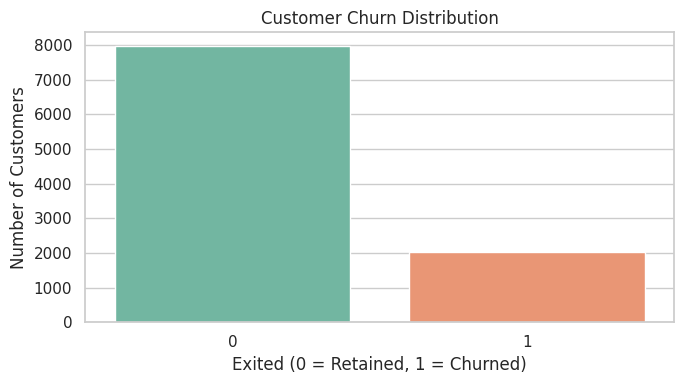

In [9]:
# Cell 6: Plot target distribution

plt.figure(figsize=(7, 4))

sns.countplot(
    data=df,
    x="Exited",
    hue="Exited",
    palette="Set2",
    legend=False
)

plt.title("Customer Churn Distribution")
plt.xlabel("Exited (0 = Retained, 1 = Churned)")
plt.ylabel("Number of Customers")
plt.tight_layout()
plt.show()

,Customers,Churned,Churn_Rate
Geography,,,
France,5014,810,16.15
Germany,2509,814,32.44
Spain,2477,413,16.67


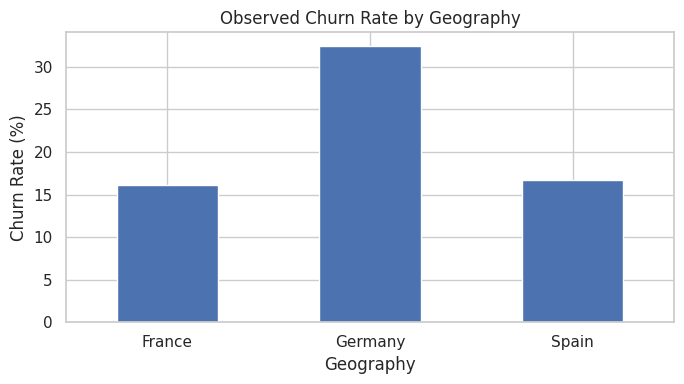

In [10]:
# Cell 7: Churn rate by geography

geo_churn = (
    df.groupby("Geography", observed=True)["Exited"]
    .agg(["count", "sum", "mean"])
    .rename(columns={
        "count": "Customers",
        "sum": "Churned",
        "mean": "Churn_Rate"
    })
)

geo_churn["Churn_Rate"] *= 100

display(geo_churn.round(2))

geo_churn["Churn_Rate"].plot(
    kind="bar",
    figsize=(7, 4),
    ylabel="Churn Rate (%)",
    title="Observed Churn Rate by Geography"
)

plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [11]:
# Cell 8: Churn by active-member status

active_churn = (
    df.groupby("IsActiveMember", observed=True)["Exited"]
    .agg(["count", "sum", "mean"])
)

active_churn.columns = [
    "Customers", "Churned", "Churn_Rate"
]

active_churn["Churn_Rate"] *= 100

display(active_churn.round(2))

,Customers,Churned,Churn_Rate
IsActiveMember,,,
0,4849,1302,26.85
1,5151,735,14.27


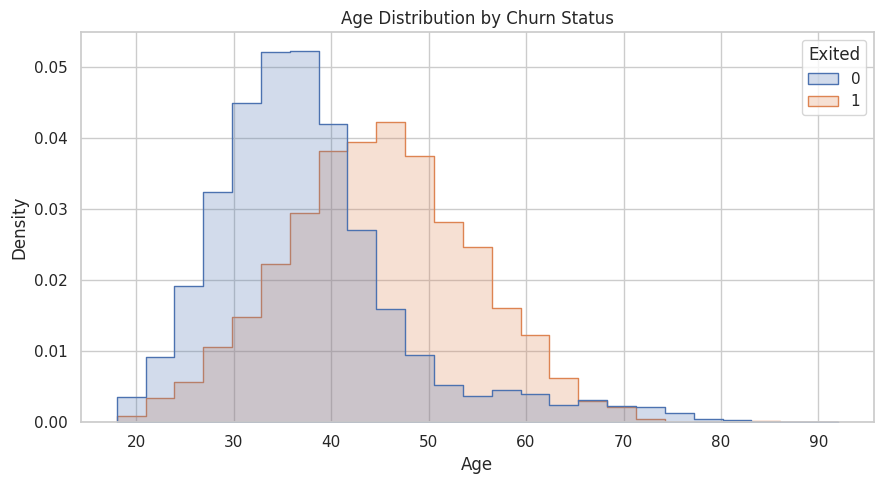

In [12]:
# Cell 9: Age distribution by churn status

plt.figure(figsize=(9, 5))

sns.histplot(
    data=df,
    x="Age",
    hue="Exited",
    bins=25,
    stat="density",
    common_norm=False,
    element="step"
)

plt.title("Age Distribution by Churn Status")
plt.xlabel("Age")
plt.ylabel("Density")
plt.tight_layout()
plt.show()

In [13]:
# Cell 10: Define features and target

target = "Exited"

# These fields identify a row/customer rather than provide
# appropriate predictors for this model.
identifier_columns = [
    "RowNumber",
    "CustomerId",
    "Surname"
]

X = df.drop(columns=[target] + identifier_columns)
y = df[target].astype(int)

print("Feature shape:", X.shape)
print("Target shape:", y.shape)

print("\nFeatures used:")
print(X.columns.tolist())

Feature shape: (10000, 10)
Target shape: (10000,)

Features used:
['CreditScore', 'Geography', 'Gender', 'Age', 'Tenure', 'Balance', 'NumOfProducts', 'HasCrCard', 'IsActiveMember', 'EstimatedSalary']


In [14]:
# Cell 11: Split data into train, validation and test sets

X_train, X_temp, y_train, y_temp = train_test_split(
    X,
    y,
    test_size=0.40,
    stratify=y,
    random_state=42
)

X_val, X_test, y_val, y_test = train_test_split(
    X_temp,
    y_temp,
    test_size=0.50,
    stratify=y_temp,
    random_state=42
)

print("Training rows:", len(X_train))
print("Validation rows:", len(X_val))
print("Test rows:", len(X_test))

print("\nChurn rates:")
print("Train:", round(y_train.mean() * 100, 2), "%")
print("Validation:", round(y_val.mean() * 100, 2), "%")
print("Test:", round(y_test.mean() * 100, 2), "%")

Training rows: 6000
Validation rows: 2000
Test rows: 2000

Churn rates:
Train: 20.37 %
Validation: 20.4 %
Test: 20.35 %


In [15]:
# Cell 12: Define preprocessing

numeric_features = X.select_dtypes(
    include=["number"]
).columns.tolist()

categorical_features = X.select_dtypes(
    include=["object", "category", "bool"]
).columns.tolist()

numeric_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer(
    transformers=[
        ("numeric", numeric_pipeline, numeric_features),
        ("categorical", categorical_pipeline, categorical_features)
    ],
    remainder="drop"
)

print("Numeric features:", numeric_features)
print("Categorical features:", categorical_features)
print("Preprocessing pipeline created.")

Numeric features: ['CreditScore', 'Age', 'Tenure', 'Balance', 'NumOfProducts', 'HasCrCard', 'IsActiveMember', 'EstimatedSalary']
Categorical features: ['Geography', 'Gender']
Preprocessing pipeline created.


In [16]:
# Cell 13: Define candidate models

models = {
    "Logistic Regression": Pipeline(steps=[
        ("preprocessor", preprocessor),
        ("classifier", LogisticRegression(
            max_iter=2000,
            class_weight=None,
            random_state=42
        ))
    ]),

    "Random Forest": Pipeline(steps=[
        ("preprocessor", preprocessor),
        ("classifier", RandomForestClassifier(
            n_estimators=300,
            min_samples_leaf=2,
            class_weight=None,
            random_state=42,
            n_jobs=-1
        ))
    ])
}

validation_results = []
fitted_models = {}

for name, pipeline in models.items():
    pipeline.fit(X_train, y_train)

    val_prob = pipeline.predict_proba(X_val)[:, 1]
    val_pred = (val_prob >= 0.5).astype(int)

    result = {
        "Model": name,
        "Accuracy": accuracy_score(y_val, val_pred),
        "Precision": precision_score(
            y_val, val_pred, zero_division=0
        ),
        "Recall": recall_score(
            y_val, val_pred, zero_division=0
        ),
        "F1": f1_score(y_val, val_pred, zero_division=0),
        "ROC_AUC": roc_auc_score(y_val, val_prob),
        "Average_Precision": average_precision_score(
            y_val, val_prob
        )
    }

    validation_results.append(result)
    fitted_models[name] = pipeline

validation_df = pd.DataFrame(validation_results)
validation_df = validation_df.sort_values(
    "ROC_AUC", ascending=False
)

display(validation_df.round(4))

,Model,Accuracy,Precision,Recall,F1,ROC_AUC,Average_Precision
1,Random Forest,0.8645,0.7625,0.4877,0.5949,0.8685,0.6950
0,Logistic Regression,0.8140,0.6233,0.2230,0.3285,0.7909,0.4994


In [17]:
# Cell 14: Select candidate with highest validation ROC-AUC

best_model_name = validation_df.iloc[0]["Model"]
best_model = fitted_models[best_model_name]

print("Selected model:", best_model_name)
print("Selection criterion: highest validation ROC-AUC")

Selected model: Random Forest
Selection criterion: highest validation ROC-AUC


In [18]:
# Cell 15: Select threshold on validation data

val_prob = best_model.predict_proba(X_val)[:, 1]

precision_values, recall_values, thresholds = (
    precision_recall_curve(y_val, val_prob)
)

# The precision-recall arrays have one more entry than thresholds.
precision_for_thresholds = precision_values[:-1]
recall_for_thresholds = recall_values[:-1]

f1_values = (
    2 * precision_for_thresholds * recall_for_thresholds
    / (
        precision_for_thresholds + recall_for_thresholds
        + 1e-12
    )
)

best_idx = int(np.argmax(f1_values))
chosen_threshold = float(thresholds[best_idx])

print(f"Chosen validation threshold: {chosen_threshold:.4f}")
print(f"Validation precision: {precision_for_thresholds[best_idx]:.4f}")
print(f"Validation recall: {recall_for_thresholds[best_idx]:.4f}")
print(f"Validation F1: {f1_values[best_idx]:.4f}")

Chosen validation threshold: 0.3575
Validation precision: 0.6485
Validation recall: 0.6422
Validation F1: 0.6453


In [19]:
# Cell 16: Final held-out test evaluation

test_prob = best_model.predict_proba(X_test)[:, 1]
test_pred = (test_prob >= chosen_threshold).astype(int)

test_metrics = {
    "Model": best_model_name,
    "Threshold": chosen_threshold,
    "Accuracy": accuracy_score(y_test, test_pred),
    "Precision": precision_score(
        y_test, test_pred, zero_division=0
    ),
    "Recall": recall_score(
        y_test, test_pred, zero_division=0
    ),
    "F1": f1_score(y_test, test_pred, zero_division=0),
    "ROC_AUC": roc_auc_score(y_test, test_prob),
    "Average_Precision": average_precision_score(
        y_test, test_prob
    )
}

test_results_df = pd.DataFrame([test_metrics])

display(test_results_df.round(4))

print("\nClassification report:")
print(classification_report(
    y_test,
    test_pred,
    target_names=["Retained", "Churned"],
    zero_division=0
))

print("Confusion matrix:")
print(confusion_matrix(y_test, test_pred))

,Model,Threshold,Accuracy,Precision,Recall,F1,ROC_AUC,Average_Precision
0,Random Forest,0.3575,0.8435,0.6211,0.5921,0.6063,0.8499,0.6764



Classification report:
              precision    recall  f1-score   support

    Retained       0.90      0.91      0.90      1593
     Churned       0.62      0.59      0.61       407

    accuracy                           0.84      2000
   macro avg       0.76      0.75      0.75      2000
weighted avg       0.84      0.84      0.84      2000

Confusion matrix:
[[1446  147]
 [ 166  241]]


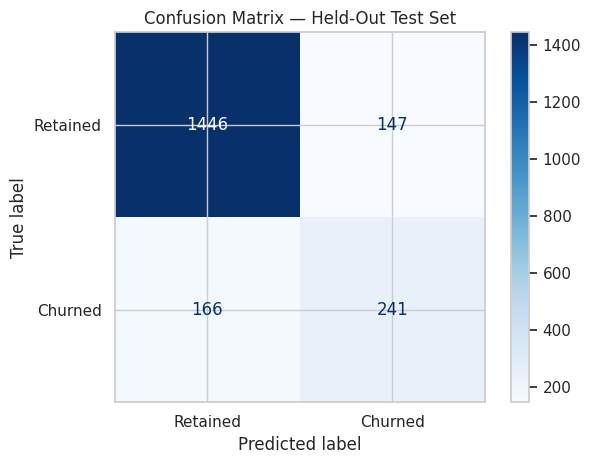

In [20]:
# Cell 17: Confusion matrix

cm = confusion_matrix(y_test, test_pred)

ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Retained", "Churned"]
).plot(cmap="Blues", values_format="d")

plt.title("Confusion Matrix — Held-Out Test Set")
plt.tight_layout()
plt.show()

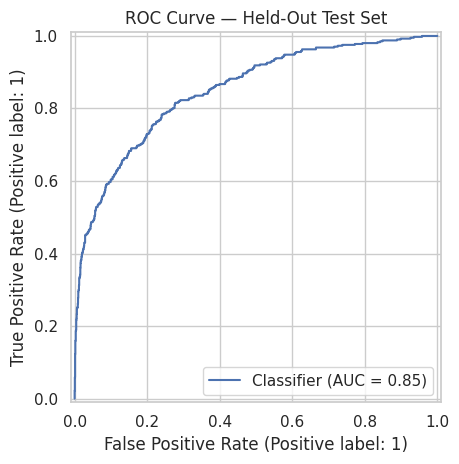

In [21]:
# Cell 18: ROC curve

RocCurveDisplay.from_predictions(y_test, test_prob)

plt.title("ROC Curve — Held-Out Test Set")
plt.tight_layout()
plt.show()

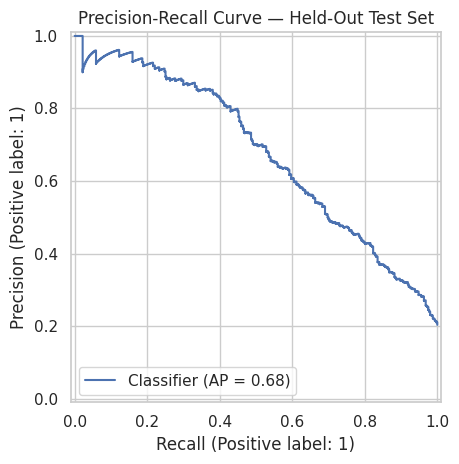

In [22]:
# Cell 19: Precision-recall curve

PrecisionRecallDisplay.from_predictions(y_test, test_prob)

plt.title("Precision-Recall Curve — Held-Out Test Set")
plt.tight_layout()
plt.show()

,Feature,Importance
1,numeric__Age,0.258663
4,numeric__NumOfProducts,0.153623
3,numeric__Balance,0.133171
7,numeric__EstimatedSalary,0.125637
0,numeric__CreditScore,0.124481
2,numeric__Tenure,0.074268
6,numeric__IsActiveMember,0.043822
9,categorical__Geography_Germany,0.027128
5,numeric__HasCrCard,0.016690
8,categorical__Geography_France,0.011732


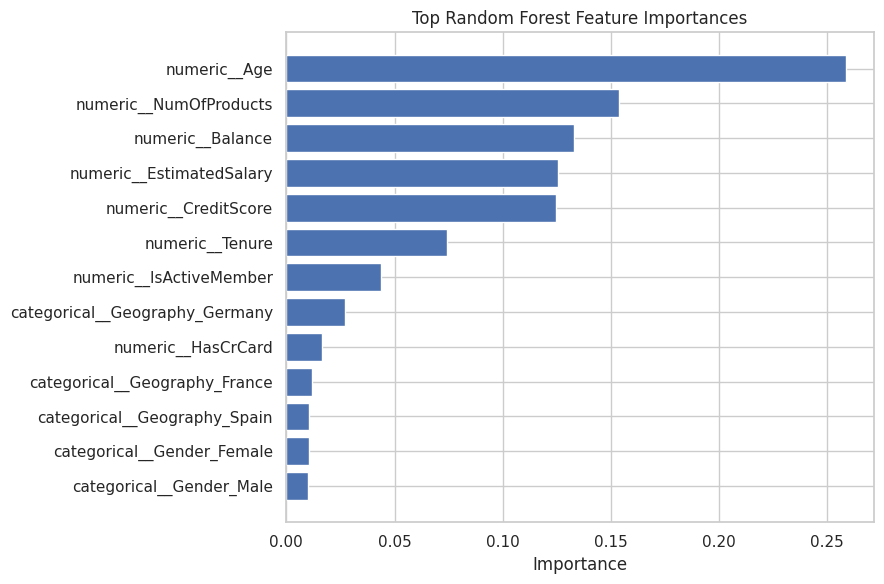

In [23]:
# Cell 20: Random Forest feature importance

if best_model_name == "Random Forest":
    fitted_preprocessor = best_model.named_steps["preprocessor"]
    fitted_classifier = best_model.named_steps["classifier"]

    feature_names = fitted_preprocessor.get_feature_names_out()
    importances = fitted_classifier.feature_importances_

    importance_df = pd.DataFrame({
        "Feature": feature_names,
        "Importance": importances
    }).sort_values("Importance", ascending=False)

    display(importance_df.head(15))

    top_features = importance_df.head(15).sort_values(
        "Importance", ascending=True
    )

    plt.figure(figsize=(9, 6))
    plt.barh(top_features["Feature"], top_features["Importance"])
    plt.title("Top Random Forest Feature Importances")
    plt.xlabel("Importance")
    plt.tight_layout()
    plt.show()
else:
    print(
        "The selected model is not Random Forest. "
        "Use a suitable explanation method for the selected model."
    )

In [24]:
# Cell 21: Save model and metadata

import joblib

os.makedirs("/content/churn_project", exist_ok=True)

model_path = "/content/churn_project/churn_model.joblib"
metrics_path = "/content/churn_project/test_metrics.json"

joblib.dump(best_model, model_path)

metadata = {
    "model_name": best_model_name,
    "target": "Exited",
    "threshold": chosen_threshold,
    "feature_columns": X.columns.tolist(),
    "metrics": {
        key: float(value)
        for key, value in test_metrics.items()
        if key != "Model"
    }
}

with open(metrics_path, "w") as f:
    json.dump(metadata, f, indent=2)

print("Saved model:", model_path)
print("Saved evaluation metrics:", metrics_path)

Saved model: /content/churn_project/churn_model.joblib
Saved evaluation metrics: /content/churn_project/test_metrics.json


In [25]:
# Cell 22: Download the model

from google.colab import files

files.download("/content/churn_project/churn_model.joblib")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [26]:
# Cell 23: Download evaluation metrics

from google.colab import files

files.download("/content/churn_project/test_metrics.json")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>